# Pediatric Psychiatric Readmission — PyHealth EHR Coding

This notebook extends `Readmission_Full_Analysis.ipynb` with PyHealth EHR coding utilities for the GD1854RVSD pediatric psychiatric rehospitalization cohort (Arizona, 2016–2021; one row per patient, *N* ≈ 2,652, ~9.3% readmitted):

**Part A — Shared modeling foundation.** Re-loads the cohort, applies the same date-quality filter and feature engineering as the main analysis, and refits the three reference models (Logistic Regression + interactions, Random Forest, CatBoost) with 10-fold *out-of-fold* (OOF) predictions.

**Part B — PyHealth EHR coding utilities (no deep nets).** Uses `pyhealth.medcode` (ICD-10-CM `InnerMap` and the ICD-10-CM → CCS `CrossMap`) to (1) *validate* the cohort's raw ICD-10 codes against the official coding system, (2) recover official descriptions for the many `[description unavailable]` placeholders in the source data, and (3) roll codes up into standardized **Clinical Classifications Software (CCS)** comorbidity groups — a recognized, reproducible grouping that complements the hand-built DSM-5 flags. The data are single-visit code *sets*, so PyHealth is used here for principled medical-code standardization rather than sequential deep models.

**Part C — Advanced statistical modeling.** Bootstrap CIs, calibration, fairness/equity, and optimism-corrected validation are now maintained exclusively in **`Readmission_ML_C_Supplements.ipynb`** to avoid duplicate `figures/AdvStats_*` outputs.

## Part A — Shared modeling foundation

Loads the cohort, applies the same data-quality filter and feature engineering as the main analysis, and refits the three reference models with 10-fold out-of-fold predictions.

In [1]:
# ── Imports & global settings ─────────────────────────────────────────────────
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import statsmodels.api as sm
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             brier_score_loss, confusion_matrix)
from sklearn.calibration import calibration_curve
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')

# Poster-quality settings (consistent with main analysis)
plt.rcParams.update({
    'font.size': 13, 'axes.titlesize': 15, 'axes.labelsize': 13,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11,
    'figure.dpi': 130, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans',
})
sns.set_style('whitegrid')
BLUE, ORANGE = '#4C72B0', '#DD8452'
MODEL_COLORS = {'Logistic Regression': '#2166ac', 'Random Forest': '#4dac26', 'CatBoost': '#d01c8b'}

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)

os.makedirs('figures', exist_ok=True)
DATA_FILE = 'data/annotated_psychiatric_data_complete.csv'
print('✓ Libraries loaded. Figures → ./figures/  | data file:', DATA_FILE)

/Users/matthewgold/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/r7/sbbjx0ls4mqck4f3x1qfjkn00000gn/T/matplotlib-zd2cnk_j because there was an issue with the default path (/Users/matthewgold/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


✓ Libraries loaded. Figures → ./figures/  | data file: annotated_psychiatric_data_complete.csv


In [2]:
# ── Load data & feature engineering (mirrors Readmission_Full_Analysis.ipynb) ──
df = pd.read_csv(DATA_FILE)

# ── Outcome ──────────────────────────────────────────────────────────────────
df['readmitted'] = (df['Readmissions'].fillna(0) > 0).astype(int)

# ── Demographics ─────────────────────────────────────────────────────────────
df['age'] = pd.to_numeric(df['Pt_Age_Visit'], errors='coerce')
df['age_group'] = pd.cut(df['age'], bins=[5, 9, 11, 13, 19],
                          labels=['6–9', '10–11', '12–13', '14+'], right=True)
df['gender_male'] = (df['GenderCode'].str.strip().str.lower() == 'male').astype(int)
df['insurance_public'] = df['Insurance'].str.contains('AHCCCS', case=False, na=False).astype(int)

# ── ACE score ────────────────────────────────────────────────────────────────
df['ace_score'] = pd.to_numeric(df['ACEscore'], errors='coerce')
df['ace_high'] = (df['ace_score'] >= 4).astype(float)

# Clinical ACE category: ACEs Aware pediatric high risk = ACE>=4 OR ACE 1–3 with a physical ACE-Associated Health Condition.
_allcodes_for_ace = (df['VisitDiags'].fillna('') + ',' + df['NonSuicidialDiags'].fillna('') + ',' + df['ChronicDiags'].fillna('')).str.upper().str.replace('.', '', regex=False)
_PHYS_AAHC = {
    'Asthma': ('J45',), 'Overweight/obesity': ('E66', 'Z684'), 'Allergy/atopy': ('J30', 'T784'),
    'Eczema/dermatitis': ('L20', 'L21', 'L23', 'L24', 'L25', 'L27', 'L28', 'L30'), 'Urticaria': ('L50',),
    'Headache/migraine': ('R51', 'G43', 'G44'), 'Somatic symptoms': ('R10', 'R11', 'R42', 'K59'),
    'Sleep disturbance': ('G47',), 'Enuresis/encopresis': ('N3944', 'R32', 'F980', 'R15', 'F981'),
    'Failure to thrive': ('R6251', 'R627', 'R633'),
}
def _has_pref(prefixes):
    return pd.Series([any(any(t.startswith(p) for t in str(s).split(',')) for p in prefixes) for s in _allcodes_for_ace], index=df.index)
_ace_cond = pd.DataFrame({k: _has_pref(v) for k, v in _PHYS_AAHC.items()})
df['has_ace_condition'] = (_ace_cond.sum(axis=1) > 0).astype(int)
def _ace_tier(a, c):
    if pd.isna(a): return np.nan
    if a == 0: return 'Low'
    if a >= 4: return 'High'
    return 'High' if c == 1 else 'Intermediate'
df['ace_risk_tier'] = [_ace_tier(a, c) for a, c in zip(df['ace_score'], df['has_ace_condition'])]
df['high_ace_expanded'] = df['ace_risk_tier'].map({'Low': 0, 'Intermediate': 0, 'High': 1})

# ── Restraints ───────────────────────────────────────────────────────────────
df['had_restraints'] = (pd.to_numeric(df['restraints'], errors='coerce').fillna(0) > 0).astype(int)

# ── C-SSRS flags ─────────────────────────────────────────────────────────────
df['csrss_yellow'] = df['Yellow flags (C-SRSS)'].notna().astype(int)
df['csrss_orange'] = df['Orange flags (C-SSRS)'].notna().astype(int)
df['csrss_red']    = df['Red flags (C-SSRS)'].notna().astype(int)
df['csrss_any']    = ((df['csrss_yellow'] + df['csrss_orange'] + df['csrss_red']) > 0).astype(int)

# ── Length of stay (compute before date-quality filter) ──────────────────────
df['VisitDate'] = pd.to_datetime(df['VisitDate'], errors='coerce')
df['DischDate'] = pd.to_datetime(df['DischDate'], errors='coerce')
df['los_days']  = (df['DischDate'] - df['VisitDate']).dt.days

# ── DATE QUALITY FILTER (same exclusions as main analysis) ───────────────────
flag_missing_visit = df['VisitDate'].isna()
flag_missing_disch = df['DischDate'].isna()
flag_negative_los  = df['los_days'].notna() & (df['los_days'] < 0)
bad = flag_missing_visit | flag_missing_disch | flag_negative_los
print(f"Date-quality exclusions: {int(bad.sum())} records "
      f"(missing visit={int(flag_missing_visit.sum())}, missing disch={int(flag_missing_disch.sum())}, "
      f"negative LOS={int(flag_negative_los.sum())})")
df = df[~bad].copy().reset_index(drop=True)

# ── Diagnostic complexity ─────────────────────────────────────────────────────
def count_csv(s):
    if pd.isna(s) or str(s).strip() == '':
        return 0
    return len([x for x in str(s).split(',') if x.strip()])

df['n_visit_diags']   = df['VisitDiags'].apply(count_csv)
df['n_chronic_diags'] = df['ChronicDiags'].apply(count_csv)
df['n_total_diags']   = df['n_visit_diags'] + df['n_chronic_diags']

def unique_dsm5_count(row):
    cats = set()
    for col in ['VisitDiags_DSM5Categories', 'ChronicDiags_DSM5Categories']:
        val = row.get(col, '')
        if pd.notna(val) and str(val).strip():
            cats.update(c.strip() for c in str(val).split(';') if c.strip())
    return len(cats)

df['n_dsm5_categories'] = df.apply(unique_dsm5_count, axis=1)

# ── DSM-5 category flags ──────────────────────────────────────────────────────
all_dsm5 = (df['VisitDiags_DSM5Categories'].fillna('') + ';' +
            df['ChronicDiags_DSM5Categories'].fillna('')).str.lower()
CATEGORY_FLAGS = {
    'has_nssi': 'non-suicidal self-injury', 'has_trauma': 'trauma and stressor',
    'has_adhd': 'adhd', 'has_asd': 'autism spectrum', 'has_conduct': 'conduct disorder',
    'has_depression': 'depressive disorders', 'has_anxiety': 'anxiety disorders',
    'has_bipolar': 'bipolar', 'has_psychotic': 'psychotic',
    'has_intellectual': 'intellectual disability', 'has_ocd': 'obsessive-compulsive',
}
for flag, kw in CATEGORY_FLAGS.items():
    df[flag] = all_dsm5.str.contains(kw, na=False).astype(int)

# ── Medical comorbidity ───────────────────────────────────────────────────────
def count_medical(s):
    if pd.isna(s) or str(s).strip() == '':
        return 0
    return sum(1 for c in str(s).split(',') if c.strip() and not c.strip().startswith('F'))

df['n_medical_chronic']       = df['ChronicDiags'].apply(count_medical)
df['has_medical_comorbidity'] = (df['n_medical_chronic'] > 0).astype(int)

print(f"✓ Feature engineering complete. N = {len(df):,} | "
      f"Readmitted = {df['readmitted'].sum():,} ({df['readmitted'].mean():.1%})")

Date-quality exclusions: 0 records (missing visit=0, missing disch=0, negative LOS=0)


✓ Feature engineering complete. N = 2,652 | Readmitted = 246 (9.3%)


In [3]:
# ── Build feature matrix + interactions, fit 3 models with 10-fold OOF preds ───
FEATURES = {
    'age': 'Age at Admission', 'gender_male': 'Male Sex',
    'insurance_public': 'Public Insurance (AHCCCS)', 'ace_score': 'ACE Score',
    'had_restraints': 'Physical Restraints', 'csrss_any': 'Any C-SSRS Flag',
    'los_days': 'Length of Stay (days)', 'n_dsm5_categories': '# DSM-5 Categories',
    'has_medical_comorbidity': 'Medical Comorbidity', 'has_nssi': 'NSSI Diagnosis',
    'has_trauma': 'Trauma/PTSD', 'has_adhd': 'ADHD', 'has_asd': 'ASD',
    'has_conduct': 'Conduct Disorder', 'has_depression': 'Depression',
    'has_anxiety': 'Anxiety', 'has_bipolar': 'Bipolar Disorder',
    'has_psychotic': 'Psychotic Disorder',
}
feat_cols = list(FEATURES.keys())
model_df = df[feat_cols + ['readmitted', 'csrss_red', 'csrss_orange', 'csrss_yellow', 'high_ace_expanded']].copy()

# Median imputation (ACE ~30% missing; documented in methods of main analysis)
model_df['ace_score'] = model_df['ace_score'].fillna(model_df['ace_score'].median())
model_df['los_days']  = model_df['los_days'].fillna(model_df['los_days'].median())
model_df = model_df.dropna().reset_index(drop=True)

# Clinically motivated interaction terms
model_df['age_x_conduct']        = model_df['age'] * model_df['has_conduct']
model_df['age_x_asd']            = model_df['age'] * model_df['has_asd']
model_df['ace_x_trauma']         = model_df['ace_score'] * model_df['has_trauma']
model_df['complexity_x_age']     = model_df['n_dsm5_categories'] * model_df['age']
model_df['csrss_level']          = (model_df['csrss_red'] * 3 + model_df['csrss_orange'] * 2
                                    + model_df['csrss_yellow'] * 1).fillna(0).astype(int)
model_df['nssi_x_csrss_red']     = model_df['has_nssi'] * model_df['csrss_red']
model_df['age_x_public_insurance'] = model_df['age'] * model_df['insurance_public']

# Keep an UNSCALED copy so subgroup thresholds/categories use real units
model_df_unscaled = model_df.copy()

interaction_keys = ['age_x_conduct', 'age_x_asd', 'ace_x_trauma',
                    'nssi_x_csrss_red', 'complexity_x_age', 'age_x_public_insurance']
all_x_cols = [c for c in feat_cols if c != 'csrss_any'] + interaction_keys + ['csrss_level']

# Standardize continuous predictors for OR interpretability
scaler = StandardScaler()
scale_cols = ['age', 'los_days', 'ace_score', 'n_dsm5_categories', 'complexity_x_age']
model_df[scale_cols] = scaler.fit_transform(model_df[scale_cols])

X_ml = model_df[all_x_cols].values
y_ml = model_df['readmitted'].values
print(f"Model dataset: {len(model_df):,} patients | {int(y_ml.sum())} readmitted "
      f"({y_ml.mean():.1%}) | {len(all_x_cols)} predictors")

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RNG_SEED)

# ── Random Forest (10-fold OOF) ───────────────────────────────────────────────
rf = RandomForestClassifier(n_estimators=500, max_depth=6, min_samples_leaf=10,
                            class_weight='balanced', random_state=RNG_SEED, n_jobs=-1)
rf_probs = np.zeros(len(y_ml))
for tr, te in cv.split(X_ml, y_ml):
    rf.fit(X_ml[tr], y_ml[tr]); rf_probs[te] = rf.predict_proba(X_ml[te])[:, 1]

# ── CatBoost (10-fold OOF) ────────────────────────────────────────────────────
def make_cat():
    return CatBoostClassifier(iterations=500, depth=4, learning_rate=0.05,
                              auto_class_weights='Balanced', eval_metric='AUC',
                              random_seed=RNG_SEED, verbose=0)
cat_probs = np.zeros(len(y_ml))
for tr, te in cv.split(X_ml, y_ml):
    m = make_cat(); m.fit(X_ml[tr], y_ml[tr]); cat_probs[te] = m.predict_proba(X_ml[te])[:, 1]

# ── Logistic Regression (10-fold OOF) ─────────────────────────────────────────
lr_probs = np.zeros(len(y_ml))
for tr, te in cv.split(X_ml, y_ml):
    Xtr = sm.add_constant(X_ml[tr], has_constant='add')
    Xte = sm.add_constant(X_ml[te], has_constant='add')
    mlr = sm.Logit(y_ml[tr], Xtr).fit(disp=0, maxiter=200)
    lr_probs[te] = mlr.predict(Xte)

# Registry of model OOF predictions used by all Part C analyses
MODELS = {'Logistic Regression': lr_probs, 'Random Forest': rf_probs, 'CatBoost': cat_probs}
for name, p in MODELS.items():
    print(f"{name:<22} AUC={roc_auc_score(y_ml, p):.3f}  AP={average_precision_score(y_ml, p):.3f}")

Model dataset: 1,569 patients | 140 readmitted (8.9%) | 24 predictors


Logistic Regression    AUC=0.633  AP=0.138
Random Forest          AUC=0.635  AP=0.140
CatBoost               AUC=0.619  AP=0.148


## Part B — PyHealth EHR coding utilities

The cohort stores diagnoses as raw ICD-10-CM code *sets* per patient (`VisitDiags`, `ChronicDiags`, `NonSuicidialDiags`). Here we use **`pyhealth.medcode`** to:

1. **Validate** every distinct code against the official ICD-10-CM vocabulary and recover official descriptions (the source file contains many `[description unavailable]` placeholders).
2. **Group** codes into standardized **Clinical Classifications Software (CCS)** categories via the ICD-10-CM → CCS `CrossMap` — a recognized, reproducible grouping that does not depend on our hand-curated DSM-5 map.
3. **Derive patient-level CCS comorbidity features** and compare them against the hand-built DSM-5 flags, including univariate readmission associations.

PyHealth resource files download on first use and are cached locally; a fallback to the repo's `comprehensive_icd_ref.pkl` / `icd_descriptions_full.json` is used if the download is unavailable.

In [4]:
# ── B1: Collect cohort ICD-10 codes & validate against PyHealth ICD-10-CM ──────
DIAG_COLS = ['VisitDiags', 'ChronicDiags', 'NonSuicidialDiags']

def parse_codes(s):
    """Split a comma-separated ICD code cell into cleaned tokens."""
    if pd.isna(s) or str(s).strip() == '':
        return []
    return [c.strip().upper() for c in str(s).split(',') if c.strip()]

# Per-patient code sets (union across the three diagnosis columns)
patient_codes = df.apply(lambda r: sorted({c for col in DIAG_COLS for c in parse_codes(r.get(col))}), axis=1)
all_codes = sorted({c for codes in patient_codes for c in codes})
print(f"Distinct ICD-10 codes in cohort: {len(all_codes):,}")

# ── Load PyHealth ICD-10-CM InnerMap (with local fallback) ────────────────────
USE_PYHEALTH = True
icd = None
try:
    from pyhealth.medcode import InnerMap, CrossMap
    icd = InnerMap.load('ICD10CM')
    print('✓ PyHealth ICD10CM InnerMap loaded.')
except Exception as e:
    USE_PYHEALTH = False
    print(f'⚠ PyHealth unavailable ({e}); falling back to local reference files.')

# Local fallback description map (used only if PyHealth fails)
local_desc = {}
try:
    import json
    with open('icd_descriptions_full.json') as fh:
        local_desc = {k.strip().upper(): v for k, v in json.load(fh).items()}
except Exception:
    pass

def pyhealth_lookup(code):
    """Return (is_valid, official_description). Tries dotted + dot-inserted variants."""
    if icd is None:
        return (code in local_desc, local_desc.get(code, ''))
    variants = [code, code.replace('.', '')]
    if '.' not in code and len(code) > 3:
        variants.append(code[:3] + '.' + code[3:])
    for v in variants:
        try:
            return True, icd.lookup(v)
        except Exception:
            continue
    return False, ''

valid_flags, descriptions = {}, {}
for c in all_codes:
    ok, desc = pyhealth_lookup(c)
    valid_flags[c] = ok
    descriptions[c] = desc

n_valid = sum(valid_flags.values())
print(f"Valid ICD-10-CM codes: {n_valid:,}/{len(all_codes):,} ({n_valid/len(all_codes):.1%})")

recon = pd.DataFrame({
    'icd_code': all_codes,
    'valid_icd10cm': [valid_flags[c] for c in all_codes],
    'pyhealth_description': [descriptions[c] for c in all_codes],
})
recon['n_patients'] = [int(sum(c in s for s in patient_codes)) for c in all_codes]
recon = recon.sort_values('n_patients', ascending=False).reset_index(drop=True)
recon.to_csv('figures/PyHealth_ICD_validation.csv', index=False)
print('✓ Saved reconciliation table → figures/PyHealth_ICD_validation.csv')
print('\nTop invalid / unmapped codes (by patient count):')
print(recon[~recon['valid_icd10cm']].head(10)[['icd_code', 'n_patients']].to_string(index=False))

Distinct ICD-10 codes in cohort: 1,863


✓ PyHealth ICD10CM InnerMap loaded.
Valid ICD-10-CM codes: 1,843/1,863 (98.9%)


✓ Saved reconciliation table → figures/PyHealth_ICD_validation.csv

Top invalid / unmapped codes (by patient count):
icd_code  n_patients
 E88.819           4
 E66.812           3
  F43.89           3
   G90.A           3
 Z91.148           2
 F50.029           2
 Z62.831           1
  R09.A2           1
 Z91.199           1
 Z79.631           1


In [5]:
# ── B2: Map ICD-10 codes to standardized CCS categories (PyHealth CrossMap) ────
ccs_map, ccs_labels = None, None
if USE_PYHEALTH:
    try:
        ccs_map = CrossMap.load('ICD10CM', 'CCSCM')
        ccs_labels = InnerMap.load('CCSCM')
        print('✓ PyHealth CrossMap ICD10CM→CCSCM and CCSCM labels loaded.')
    except Exception as e:
        print(f'⚠ CCS mapping unavailable ({e}); CCS features will be skipped.')

def code_to_ccs(code):
    """Map one ICD-10-CM code to (ccs_code, ccs_label) or (None, None)."""
    if ccs_map is None:
        return (None, None)
    variants = [code, code.replace('.', '')]
    if '.' not in code and len(code) > 3:
        variants.append(code[:3] + '.' + code[3:])
    for v in variants:
        try:
            mapped = ccs_map.map(v)
        except Exception:
            mapped = []
        if mapped:
            cc = mapped[0]
            try:
                lab = ccs_labels.lookup(cc)
            except Exception:
                lab = cc
            return (cc, lab)
    return (None, None)

code2ccs = {c: code_to_ccs(c) for c in all_codes}

# ── Decompose CCS 653 "Residual codes; unclassified" into meaningful groups ──
# PyHealth routes a HETEROGENEOUS set of codes to this catch-all: organic F-codes
# (neurocognitive disorders), sleep-wake (G47), symptom (R-), and psychosocial (Z-).
# Treating them as one comorbidity is misleading; relabel by code family.
def _reclass_residual(code, label):
    if label is None or 'residual' not in str(label).lower():
        return None                       # only decompose the residual bucket
    c = code.replace('.', '').upper()
    if c.startswith(('F02','F03','F05','F07','F09')) or c in ('R413','R4182','R404'):
        return ('NEURO_DX', 'Neurocognitive Disorders')
    if c.startswith('G47'):
        return ('SLEEP_DX', 'Sleep-Wake Disorders')
    if c.startswith('Z'):
        return ('ZSTATUS', 'Status/psychosocial (Z-codes)')
    return None                            # leave true residual as-is

_recl = {}
for _c in list(code2ccs.keys()):
    _new = _reclass_residual(_c, code2ccs.get(_c, (None, None))[1])
    if _new is not None:
        code2ccs[_c] = _new
        _recl.setdefault(_new[1], []).append(_c)

# Eliminate the catch-all entirely: relabel any remaining "Residual codes" by family
for _c in list(code2ccs.keys()):
    _cc, _lab = code2ccs.get(_c, (None, None))
    if _lab and 'residual' in str(_lab).lower():
        _n = _c.replace('.', '').upper()
        code2ccs[_c] = ('OTHER_SX', 'Other symptoms/signs') if _n.startswith('R')                        else ('OTHER_UNCL', 'Other/unclassified (non-specific)')

print("CCS 653 decomposition:")
for _k, _v in _recl.items():
    print(f"   {_k}: {len(_v)} codes  e.g. {sorted(_v)[:4]}")

n_ccs_mapped = sum(1 for v in code2ccs.values() if v[0] is not None)
print(f"Codes mapped to a CCS category: {n_ccs_mapped:,}/{len(all_codes):,} "
      f"({n_ccs_mapped/len(all_codes):.1%})")

# Attach CCS columns to the reconciliation table
recon['ccs_code']  = recon['icd_code'].map(lambda c: code2ccs[c][0])
recon['ccs_label'] = recon['icd_code'].map(lambda c: code2ccs[c][1])
recon.to_csv('figures/PyHealth_ICD_validation.csv', index=False)

# Cohort-level CCS prevalence (patient-weighted)
ccs_patient_counts = {}
for codes in patient_codes:
    cats = {code2ccs[c][1] for c in codes if code2ccs.get(c, (None, None))[0] is not None}
    for cat in cats:
        ccs_patient_counts[cat] = ccs_patient_counts.get(cat, 0) + 1

ccs_prev = (pd.Series(ccs_patient_counts).sort_values(ascending=False)
            .rename('n_patients').to_frame())
ccs_prev['pct_patients'] = (ccs_prev['n_patients'] / len(df) * 100).round(1)
print(f"\nDistinct CCS categories present in cohort: {len(ccs_prev)}")
print('\nTop 15 CCS categories by patient prevalence:')
print(ccs_prev.head(15).to_string())

✓ PyHealth CrossMap ICD10CM→CCSCM and CCSCM labels loaded.
CCS 653 decomposition:
   Sleep-Wake Disorders: 15 codes  e.g. ['G47.00', 'G47.01', 'G47.10', 'G47.11']
   Neurocognitive Disorders: 3 codes  e.g. ['R40.4', 'R41.3', 'R41.82']
   Status/psychosocial (Z-codes): 51 codes  e.g. ['Z14.1', 'Z14.8', 'Z15.89', 'Z28.82']
Codes mapped to a CCS category: 1,719/1,863 (92.3%)

Distinct CCS categories present in cohort: 177

Top 15 CCS categories by patient prevalence:
                                                       n_patients  pct_patients
Mood disorders                                               1827          68.9
Anxiety disorders                                            1700          64.1
"Attention-deficit                                           1637          61.7
Suicide and intentional self-inflicted injury                1428          53.8
"Disorders usually diagnosed in infancy                       843          31.8
Administrative/social admission                    

In [6]:
# ── B3: Build patient-level CCS comorbidity features ──────────────────────────
TOP_K_CCS = 15
top_ccs = list(ccs_prev.head(TOP_K_CCS).index) if len(ccs_prev) else []

# Per-patient set of CCS categories (aligned with df)
patient_ccs_sets = [
    {code2ccs[c][1] for c in codes if code2ccs.get(c, (None, None))[0] is not None}
    for codes in patient_codes
]

ccs_features = pd.DataFrame(index=df.index)
ccs_features['readmitted'] = df['readmitted'].values
# Standardized comorbidity complexity = # distinct CCS categories
ccs_features['n_ccs_categories'] = [len(s) for s in patient_ccs_sets]

def ccs_colname(label):
    slug = ''.join(ch if ch.isalnum() else '_' for ch in str(label).lower())
    return 'ccs__' + slug[:40].strip('_')

ccs_feature_cols = []
for cat in top_ccs:
    col = ccs_colname(cat)
    ccs_features[col] = [1 if cat in s else 0 for s in patient_ccs_sets]
    ccs_feature_cols.append(col)

print(f"Built {len(ccs_feature_cols)} CCS indicator features + n_ccs_categories.")
print(f"Patients with >=1 mapped CCS category: "
      f"{(ccs_features['n_ccs_categories'] > 0).mean():.1%}")
print(f"Median distinct CCS categories / patient: "
      f"{ccs_features['n_ccs_categories'].median():.0f} "
      f"(IQR {ccs_features['n_ccs_categories'].quantile(0.25):.0f}"
      f"–{ccs_features['n_ccs_categories'].quantile(0.75):.0f})")
ccs_features.to_csv('figures/PyHealth_CCS_patient_features.csv', index=False)
print('✓ Saved patient-level CCS features → figures/PyHealth_CCS_patient_features.csv')
ccs_features.head()

Built 15 CCS indicator features + n_ccs_categories.
Patients with >=1 mapped CCS category: 100.0%
Median distinct CCS categories / patient: 5 (IQR 4–7)
✓ Saved patient-level CCS features → figures/PyHealth_CCS_patient_features.csv


,readmitted,n_ccs_categories,ccs__mood_disorders,ccs__anxiety_disorders,ccs__attention_deficit,ccs__suicide_and_intentional_self_inflicted_i,ccs__disorders_usually_diagnosed_in_infancy,ccs__administrative_social_admission,ccs__adjustment_disorders,ccs__other_nutritional__endocrine__and_metabo,ccs__other_gastrointestinal_disorders,ccs__developmental_disorders,ccs__impulse_control_disorders,ccs__status_psychosocial__z_codes,ccs__other_symptoms_signs,ccs__other_nervous_system_disorders,ccs__blindness_and_vision_defects
0,0,10,1,1,0,1,0,0,0,0,1,0,0,1,0,0,1
1,0,2,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2,0,4,1,0,0,1,0,1,0,0,0,0,0,0,1,0,0
3,0,8,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0
4,0,6,1,1,0,1,1,0,0,0,0,0,0,0,0,0,0


Univariate readmission association by CCS category (Haldane-corrected ORs):
                                 CCS category  N exposed  Readmit% (exposed)  Readmit% (unexposed)    OR  OR_lo  OR_hi     p
      "Disorders usually diagnosed in infancy        843              13.998                 7.076 2.137  1.641  2.784 0.000
                               Mood disorders       1827              10.837                 5.818 1.953  1.410  2.704 0.000
                      Developmental disorders        295              15.254                 8.528 1.944  1.374  2.751 0.000
                   "Impulse control disorders        293              15.017                 8.563 1.900  1.339  2.697 0.000
                            Anxiety disorders       1700              11.000                 6.197 1.860  1.374  2.519 0.000
                           "Attention-deficit       1637              11.118                 6.305 1.850  1.377  2.485 0.000
                 Blindness and vision defects    

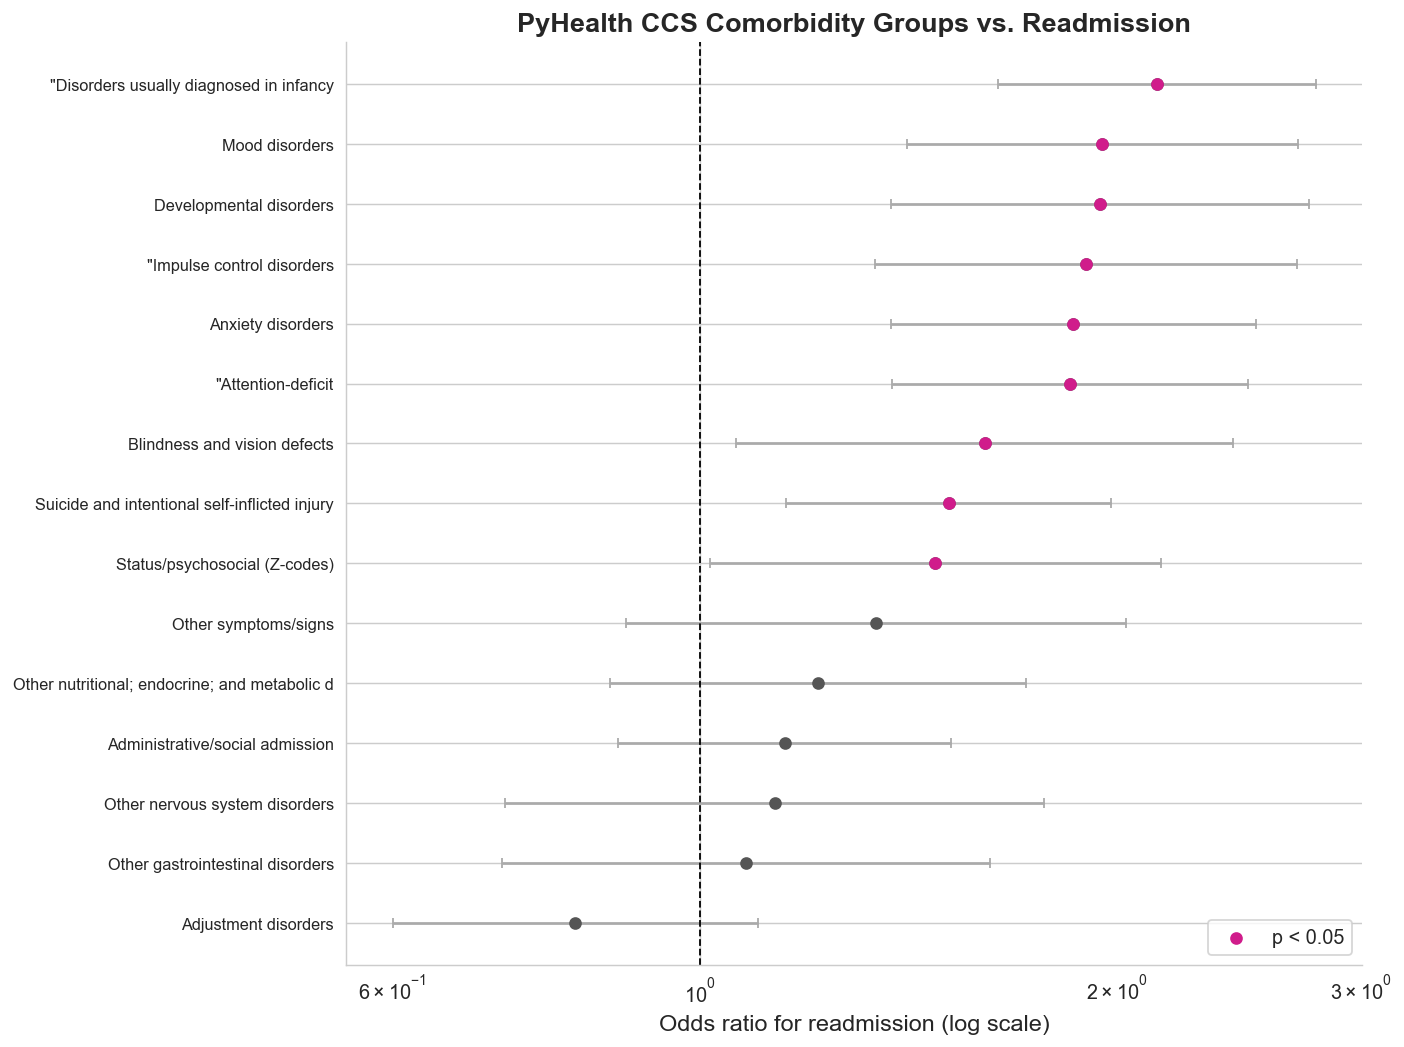


Incremental predictive value (10-fold OOF logistic AUC):
  Base (demographic + clinical)      AUC = 0.548
  Base + hand-built DSM-5 flags      AUC = 0.660


  Base + PyHealth CCS features       AUC = 0.693
  Base + DSM-5 + CCS                 AUC = 0.697


In [7]:
# ── B4: CCS readmission associations + comparison vs DSM-5 flags ──────────────
from statsmodels.stats.contingency_tables import Table2x2
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict

y_b = ccs_features['readmitted'].values

# (a) Univariate odds ratios for each top CCS category
rows = []
for cat, col in zip(top_ccs, ccs_feature_cols):
    x = ccs_features[col].values
    a = int(((x == 1) & (y_b == 1)).sum()); b = int(((x == 1) & (y_b == 0)).sum())
    c = int(((x == 0) & (y_b == 1)).sum()); d = int(((x == 0) & (y_b == 0)).sum())
    tbl = Table2x2(np.array([[a + 0.5, b + 0.5], [c + 0.5, d + 0.5]]))  # Haldane correction
    rate_in  = a / (a + b) if (a + b) else np.nan
    rate_out = c / (c + d) if (c + d) else np.nan
    rows.append({'CCS category': cat[:45], 'N exposed': a + b,
                 'Readmit% (exposed)': rate_in * 100, 'Readmit% (unexposed)': rate_out * 100,
                 'OR': tbl.oddsratio, 'OR_lo': tbl.oddsratio_confint()[0],
                 'OR_hi': tbl.oddsratio_confint()[1], 'p': tbl.oddsratio_pvalue()})
ccs_assoc = pd.DataFrame(rows).sort_values('OR', ascending=False).reset_index(drop=True)
ccs_assoc.to_csv('figures/PyHealth_CCS_associations.csv', index=False)
print('Univariate readmission association by CCS category (Haldane-corrected ORs):')
print(ccs_assoc.round(3).to_string(index=False))

# Forest plot of CCS odds ratios
fig, ax = plt.subplots(figsize=(11, max(5, 0.55 * len(ccs_assoc))))
ypos = np.arange(len(ccs_assoc))[::-1]
sig = ccs_assoc['p'] < 0.05
ax.errorbar(ccs_assoc['OR'], ypos,
            xerr=[ccs_assoc['OR'] - ccs_assoc['OR_lo'], ccs_assoc['OR_hi'] - ccs_assoc['OR']],
            fmt='o', color='#555', ecolor='#aaa', capsize=3, zorder=2)
ax.scatter(ccs_assoc.loc[sig, 'OR'], ypos[sig.values], color='#d01c8b', zorder=3,
           label='p < 0.05')
ax.axvline(1.0, color='k', ls='--', lw=1)
ax.set_yticks(ypos)
ax.set_yticklabels(ccs_assoc['CCS category'], fontsize=9)
ax.set_xscale('log'); ax.set_xlabel('Odds ratio for readmission (log scale)')
ax.set_title('PyHealth CCS Comorbidity Groups vs. Readmission', fontweight='bold')
ax.legend(loc='lower right')
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
plt.subplots_adjust(left=0.42)
plt.tight_layout()
plt.savefig('figures/PyHealth_CCS_forest.png')
plt.show()

# (b) Incremental value: does standardized CCS encoding add signal vs hand-built flags?
base_cols = ['age', 'gender_male', 'insurance_public', 'ace_score', 'had_restraints',
             'csrss_any', 'los_days']
dsm5_cols = [c for c in CATEGORY_FLAGS]  # hand-built DSM-5 flags
base_df = df.copy()
base_df['ace_score'] = base_df['ace_score'].fillna(base_df['ace_score'].median())
base_df['los_days']  = base_df['los_days'].fillna(base_df['los_days'].median())

def oof_auc(Xcols_frame):
    Xv = Xcols_frame.values.astype(float)
    lr = LogisticRegression(max_iter=2000, class_weight='balanced')
    p = cross_val_predict(lr, Xv, y_b, cv=cv, method='predict_proba')[:, 1]
    return roc_auc_score(y_b, p)

feature_sets = {
    'Base (demographic + clinical)': base_df[base_cols],
    'Base + hand-built DSM-5 flags': pd.concat([base_df[base_cols], base_df[dsm5_cols]], axis=1),
    'Base + PyHealth CCS features':  pd.concat([base_df[base_cols].reset_index(drop=True),
                                                ccs_features[['n_ccs_categories'] + ccs_feature_cols]], axis=1),
    'Base + DSM-5 + CCS':            pd.concat([base_df[base_cols].reset_index(drop=True),
                                                base_df[dsm5_cols].reset_index(drop=True),
                                                ccs_features[['n_ccs_categories'] + ccs_feature_cols]], axis=1),
}
print('\nIncremental predictive value (10-fold OOF logistic AUC):')
for name, frame in feature_sets.items():
    print(f"  {name:<34} AUC = {oof_auc(frame):.3f}")

## Part C — Advanced statistical modeling

Advanced statistical validation (bootstrap CIs, calibration metrics, fairness/equity panel, and optimism-corrected validation) is fully implemented in **`Readmission_ML_C_Supplements.ipynb`**, which is the canonical source for all `figures/AdvStats_*` outputs (C1–C4 supplement section).

This notebook focuses exclusively on Part B (PyHealth EHR/CCS coding). To reproduce bootstrap CIs, calibration metrics, the equity panel, or optimism-corrected AUCs, run `Readmission_ML_C_Supplements.ipynb`.

## Summary & saved artifacts

**Part B (PyHealth EHR coding).** `pyhealth.medcode` validated the cohort's raw ICD-10 codes against the official vocabulary, recovered standardized descriptions, and grouped codes into reproducible CCS comorbidity categories — a principled, externally-defined feature set that complements the hand-curated DSM-5 flags and lets us check how much predictive signal is encoding-dependent.

**Part C (advanced statistics).** Moved to `Readmission_ML_C_Supplements.ipynb` to maintain a single source of truth for `figures/AdvStats_*` outputs. Run that notebook for bootstrap CIs, calibration metrics, equity panel, and optimism-corrected validation.

**Saved files** (in `./figures/`): `PyHealth_ICD_validation.csv`, `PyHealth_CCS_patient_features.csv`, `PyHealth_CCS_associations.csv`, `PyHealth_CCS_forest.png`.

> **Caveat.** This is a single-site, cross-sectional, single-visit cohort with a low event count; all estimates are exploratory and require external/temporal validation before any clinical use.